Age:  Mean: 49.43, Median: 50.0, Min: 18, Max: 90
Height:  Mean: 171.85, Median: 171.35, Min: 144.4, Max: 200.4
Weight:  Mean: 73.41, Median: 73.2, Min: 33.7, Max: 114.4
Blood Pressure:  Mean: 149.18, Median: 149.4, Min: 106.8, Max: 185.9
Cholesterol:  Mean: 4.93, Median: 4.97, Min: 2.5, Max: 7.88


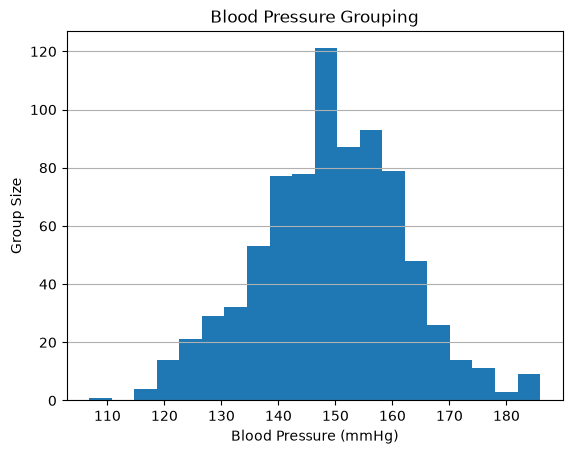

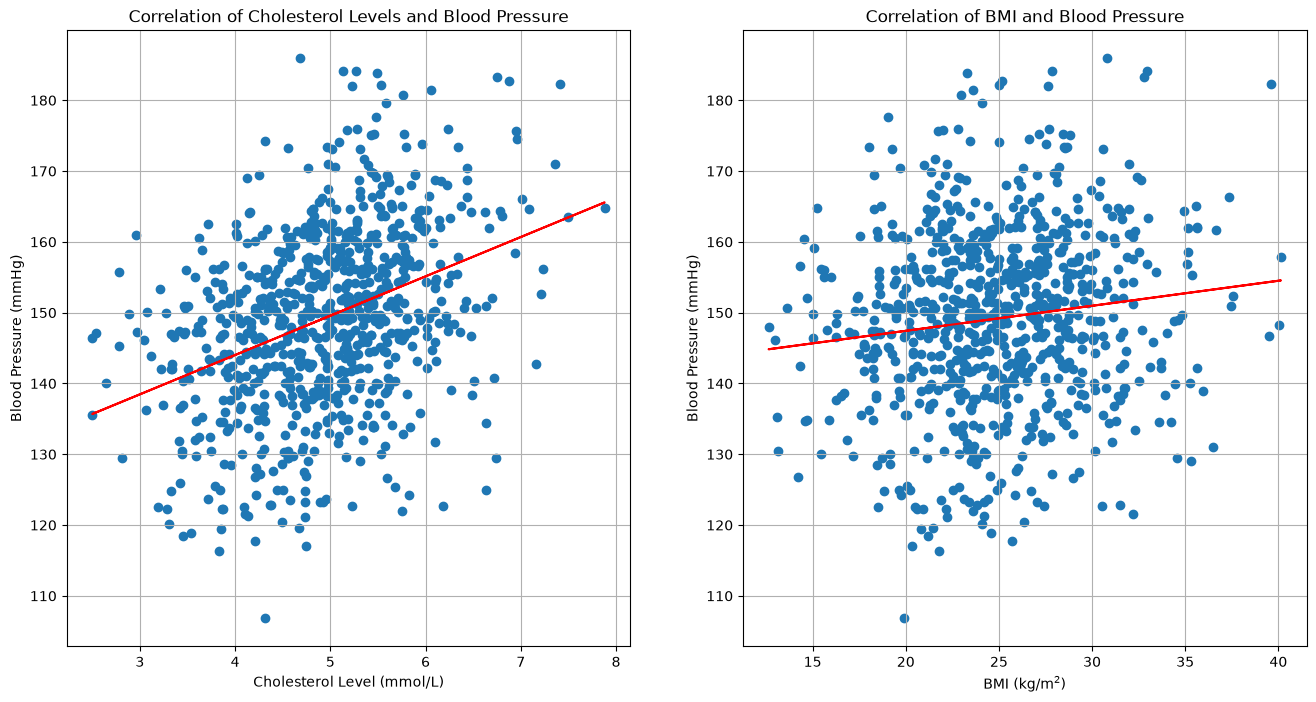

sex     smoker
Female  0         287
        1         116
Male    0         300
        1          97
dtype: int64
sex     disease
Female  0          385
        1           18
Male    0          368
        1           29
dtype: int64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from src import io_functions, viz
from src.viz import GraphTexts

raw = pd.read_csv("data/health_study_dataset.csv")
df = io_functions.clean_data(raw)

io_functions.compose_values(df["age"], "Age")
io_functions.compose_values(df["height"], "Height")
io_functions.compose_values(df["weight"], "Weight")
io_functions.compose_values(df["systolic_bp"], "Blood Pressure")
io_functions.compose_values(df["cholesterol"], "Cholesterol")

fig, ax = plt.subplots()
viz.hist(
	ax,
    df["systolic_bp"],
    20,
    GraphTexts(
		"Blood Pressure Grouping",
        "Blood Pressure (mmHg)",
        "Group Size"
    )
)
plt.show()

fig, axs = plt.subplots(1, 2, figsize=[16, 8])
viz.scatter(
	axs[0],
    df["cholesterol"],
    df["systolic_bp"],
    GraphTexts(
		"Correlation of Cholesterol Levels and Blood Pressure",
        "Cholesterol Level (mmol/L)",
        "Blood Pressure (mmHg)"
    ),
    True
)
bmi = df["weight"] / ((df["height"] / 100) ** 2)
viz.scatter(
	axs[1],
    bmi,
    df["systolic_bp"],
    GraphTexts(
		"Correlation of BMI and Blood Pressure",
        r"BMI (kg/m$^{2}$)",
        "Blood Pressure (mmHg)"
    ),
    True
)
plt.show()

smokers_by_sex = df.sort_values(["sex", "smoker"]).groupby(["sex", "smoker"])
print(smokers_by_sex.size())
# fig, ax = plt.subplots()
# viz.grouped_bar(
# 	ax,
#     smokers_by_sex,
#     GraphTexts(
# 		"Smokers by Sex",
#         "Sex",
#         "Group Size"
#     )
# )
# plt.show()

disease_rate_by_sex = df.sort_values(["sex", "disease"]).groupby(["sex", "disease"])
print(disease_rate_by_sex.size())
# fig, ax = plt.subplots()
# viz.grouped_bar(
#     ax,
#     disease_rate_by_sex,
#     GraphTexts(
# 		"Diseased by Sex",
# 		"Sex",
# 		"Group Size"
#     )
# )
# plt.show()


In [ ]:
import random
from src.person import Person

random.seed(42)

Age_MINMAX = io_functions.minmax(df["age"])
HEIGHT_MINMAX = io_functions.minmax(df["height"])
WEIGHT_MINMAX = io_functions.minmax(df["weight"])
BP_MINMAX = io_functions.minmax(df["systolic_bp"])
CHOLESTEROL_MINMAX = io_functions.minmax(df["cholesterol"])
SMOKER_RATE = (10., 10.)
DISEASE_RATE = 5.

random_people: list[Person] = []
for i in range(1000):
    person = Person()
    person.generate_random_person(
        age_range=(Age_MINMAX),
        height_range=(HEIGHT_MINMAX),
        weight_range=(WEIGHT_MINMAX),
        bp_range=(BP_MINMAX),
        cholesterol_range=(CHOLESTEROL_MINMAX),
        smoker_rate_by_gender=(SMOKER_RATE),
        disease_rate=DISEASE_RATE)
    random_people.append(person)

print(random_people[60])

Age: 69
Sex: Female
Height: 145
Weight: 47
BP: 139
Cholesterol: 2.91
Smoker: 0
Disease: 0
